# Task 3 — Modelos individuais e de ensemble

## 3.1 Modelos individuais

Esta secção implementa três classificadores individuais que representam princípios diferentes (linear, probabilístico e árvore de decisão), preparados para serem avaliados nos mesmos folds temporais definidos na Task 2. A escolha de cada algoritmo é justificada em relação aos dados, ao desequilíbrio de classes, aos pressupostos, à interpretabilidade e ao custo computacional.

A avaliação comparativa completa (PR-AUC, precision, recall, F1, F2 e ROC-AUC) fica para a secção seguinte. Aqui guardam-se as probabilidades previstas em cada fold, para que todas as métricas sejam calculadas a partir das mesmas previsões.

### 1. Dados, alvo e folds da Task 2

O alvo, os preditores elegíveis e os folds são reconstruídos como na Task 2 (secções 4 e 8). Os folds são comparados com `validation_protocol_task2.json`, para garantir que as divisões são exatamente as do protocolo. O teste final (a partir de 2021-08-01) não é usado nesta secção.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", message="A worker stopped")

DATA_PATH = Path("Charging_Data_educational.csv")
protocol = json.loads(Path("validation_protocol_task2.json").read_text(encoding="utf-8"))
eligible_predictors = json.loads(Path("predictors_task2.json").read_text(encoding="utf-8"))["eligible_predictors"]

df = pd.read_csv(DATA_PATH)
df.columns = (
    df.columns.astype(str).str.strip().str.lower()
    .str.replace(r"[^a-zA-Z0-9]+", "_", regex=True).str.strip("_")
)
start_dt = pd.to_datetime(df["start_time"])
end_dt = pd.to_datetime(df["end_time"])

NORMAL_END_CAUSES = {"Charging ends normally", "User stops charging"}
y = (~df["end_cause"].isin(NORMAL_END_CAUSES)).astype(int)

CATEGORICAL = ["charging_post_id", "location_information", "district_name", "tariff_period"]


def build_features(frame):
    X = frame[eligible_predictors].copy()
    hour = start_dt.dt.hour + start_dt.dt.minute / 60
    X["hour_sin"], X["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
    X["weekday_sin"] = np.sin(2 * np.pi * start_dt.dt.weekday / 7)
    X["weekday_cos"] = np.cos(2 * np.pi * start_dt.dt.weekday / 7)
    X = X.drop(columns="start_time")
    X[CATEGORICAL] = X[CATEGORICAL].astype(str)
    numeric = [col for col in X.columns if col not in CATEGORICAL]
    X[numeric] = X[numeric].astype(float)
    return X


X = build_features(df)
numeric_cols = [col for col in X.columns if col not in CATEGORICAL]

TEST_START = pd.Timestamp(protocol["test_start"])
N_FOLDS, FOLD_MONTHS = protocol["n_folds"], protocol["fold_months"]
val_starts = [TEST_START - pd.DateOffset(months=FOLD_MONTHS * (N_FOLDS - k)) for k in range(N_FOLDS)]
val_ends = val_starts[1:] + [TEST_START]

folds = []
for v_start, v_end in zip(val_starts, val_ends):
    val_idx = np.flatnonzero(((start_dt >= v_start) & (start_dt < v_end)).to_numpy())
    train_idx = np.flatnonzero(((start_dt < v_start) & (end_dt < v_start)).to_numpy())
    folds.append((train_idx, val_idx))

for k, (tr, va) in enumerate(folds):
    expected = protocol["folds"][k]
    assert (len(tr), len(va)) == (expected["n_treino"], expected["n_validacao"]), f"fold {k + 1} difere do protocolo"
dev_mask = (start_dt < TEST_START).to_numpy()

print(f"Folds idênticos ao protocolo da Task 2: {[(len(t), len(v)) for t, v in folds]}")
print(f"Preditores: {X.shape[1]} ({len(numeric_cols)} numéricos, {len(CATEGORICAL)} categóricos) | prevalência: {y.mean():.2%}")

Folds idênticos ao protocolo da Task 2: [(79695, 66045), (145748, 57027), (202793, 42189), (244950, 64938)]
Preditores: 40 (36 numéricos, 4 categóricos) | prevalência: 18.58%


### 2. Evidência dos dados para a escolha dos modelos

Os pressupostos de cada modelo são verificados nos dados de desenvolvimento (antes de `TEST_START`), em vez de assumidos: cardinalidade das categóricas, assimetria das variáveis contínuas, valores em falta e correlação entre preditores.

In [2]:
dev = X[dev_mask]
binary_cols = [col for col in numeric_cols if col.startswith("is_") or "no_previous" in col]
continuous_cols = [col for col in numeric_cols if col not in binary_cols]

print("Cardinalidade das variáveis categóricas:")
display(dev[CATEGORICAL].nunique().rename("categorias").to_frame())

missing = dev[numeric_cols].isna().mean().rename("em_falta")
print("Colunas numéricas com valores em falta (têm indicador de ausência de histórico):")
display(missing[missing > 0].to_frame().style.format("{:.2%}"))

skew = dev[continuous_cols].skew().abs()
print(f"Variáveis contínuas: {len(continuous_cols)} | com |assimetria| > 2: {(skew > 2).sum()} "
      f"| assimetria mediana: {skew.median():.2f}")

corr = dev[continuous_cols].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = pairs[pairs >= 0.9]
print(f"Pares de variáveis contínuas com |r| >= 0.90: {len(strong)} de {len(pairs)}")
display(strong.sort_values(ascending=False).head(8).rename("|r|").to_frame())

Cardinalidade das variáveis categóricas:


,categorias
charging_post_id,92
location_information,13
district_name,3
tariff_period,7


Colunas numéricas com valores em falta (têm indicador de ausência de histórico):


,em_falta
post_hours_since_previous_completed_session,0.03%
post_hours_since_previous_completed_abnormal,0.12%
user_days_since_previous_completed_session,12.86%
user_days_since_previous_completed_abnormal,30.73%


Variáveis contínuas: 31 | com |assimetria| > 2: 17 | assimetria mediana: 2.20


Pares de variáveis contínuas com |r| >= 0.90: 4 de 961


,,|r|
user_previous_sessions_730d,user_previous_abnormal_730d,0.995905
user_previous_sessions_180d,user_previous_abnormal_180d,0.990159
user_previous_abnormal_rate_180d,user_previous_abnormal_rate_730d,0.978509
user_previous_sessions_30d,user_previous_abnormal_30d,0.964764


**Leitura.** Mais de metade das variáveis contínuas (17 de 31) tem assimetria superior a 2 (contagens de sessões e de anomalias), e há 4 pares com $|r| \geq 0{,}90$: sessões e anomalias na mesma janela do utilizador, e taxas de janelas longas do utilizador. Há valores em falta apenas nas colunas de recência, que têm indicadores de ausência de histórico. As categóricas têm cardinalidade baixa, exceto `charging_post_id` (um valor por posto).

Estes factos orientam a escolha dos modelos na secção seguinte.

### 3. Escolha e justificação dos modelos

| Princípio | Modelo | Porquê neste problema | Pressupostos e riscos | Interpretabilidade | Custo |
|---|---|---|---|---|---|
| Linear | Regressão logística (modelo de referência da Task 2) | Mistura de numéricas e categóricas resolvida com escala e *one-hot*; produz probabilidades diretamente utilizáveis no limiar por custos da secção 6 | Relação linear nos log-odds; sensível a escala e a contagens assimétricas; não capta interações (por exemplo posto × histórico) | Alta: um coeficiente por variável | Baixo |
| Probabilístico | Naive Bayes Gaussiano | Representa um princípio diferente (regra de Bayes com verosimilhança por classe) e serve de referência barata | Independência condicional dos preditores e distribuição normal por classe; os dados mostram variáveis assimétricas e alguns pares muito correlacionados, por isso os pressupostos não se verificam por completo e as probabilidades tendem a ser extremas | Média: parâmetros por classe | Muito baixo |
| Árvore de decisão | `DecisionTreeClassifier` com profundidade limitada | Capta não linearidades e interações sem pressupostos de distribuição, é insensível à escala e às contagens assimétricas e não é afetada por variáveis redundantes | Sobreajuste se crescer sem limite e instabilidade; a profundidade e `min_samples_leaf` limitam-no e evitam probabilidades de 0 ou 1 | Alta se pouco profunda: regras legíveis | Baixo |

**Alternativas não incluídas.** Os métodos baseados em instâncias (k-NN) e os de *kernel* (SVM) exigem calcular distâncias ou uma matriz de *kernel* sobre até cerca de 245 mil sessões de treino, com 4 categóricas e dezenas de contagens assimétricas, algumas redundantes, o que torna as distâncias pouco informativas e o custo elevado. Com três princípios bem justificados, não se acrescentam mais algoritmos.

**Desequilíbrio de classes.** A classe anormal representa cerca de 18,6% das sessões, um desequilíbrio moderado. Não se usa reponderação nem *resampling*: a métrica principal (PR-AUC) depende apenas da ordenação das probabilidades, e o limiar por custos definido na Task 2 ($1/(1+4)$) assume probabilidades coerentes com a prevalência real, o que a reponderação alteraria. O limiar é tratado na avaliação.

**Regra de seleção de hiperparâmetros.** Só dois pontos são ajustados, e apenas com os folds de validação: a profundidade da árvore e a inclusão de `charging_post_id` no Naive Bayes. O teste final não é usado.

### 4. Implementação

Cada modelo tem o pré-processamento adequado aos seus pressupostos, ajustado dentro do `Pipeline` apenas com o treino de cada fold:

- **Regressão logística:** mediana + padronização nas numéricas e *one-hot* nas categóricas (igual ao modelo de referência da Task 2).
- **Naive Bayes:** mediana nas numéricas (o modelo é invariante à escala) e *one-hot* denso nas categóricas.
- **Árvore:** mediana nas numéricas e codificação ordinal nas categóricas (a árvore parte por limiares e dispensa *one-hot*).

In [3]:
RANDOM_STATE = 42
TREE_MIN_SAMPLES_LEAF = 200


def numeric_scaled():
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])


def make_logistic():
    prep = ColumnTransformer([
        ("num", numeric_scaled(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATEGORICAL),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))])


def make_naive_bayes(with_post_id=False):
    categorical = CATEGORICAL if with_post_id else [col for col in CATEGORICAL if col != "charging_post_id"]
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False), categorical),
    ])
    return Pipeline([("prep", prep), ("clf", GaussianNB())])


def make_tree(max_depth):
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL),
    ])
    clf = DecisionTreeClassifier(
        max_depth=max_depth, min_samples_leaf=TREE_MIN_SAMPLES_LEAF, random_state=RANDOM_STATE
    )
    return Pipeline([("prep", prep), ("clf", clf)])


def cross_val_predict_folds(make_model):
    """Probabilidade da classe anormal em cada fold de validação, com ajuste só no treino do fold."""
    predictions, fit_seconds = [], []
    for train_idx, val_idx in folds:
        started = time.perf_counter()
        model = make_model().fit(X.iloc[train_idx], y.iloc[train_idx])
        fit_seconds.append(time.perf_counter() - started)
        predictions.append(model.predict_proba(X.iloc[val_idx])[:, 1])
    return {"pred": predictions, "fit_s": float(np.mean(fit_seconds))}


def pr_auc_by_fold(result):
    return [average_precision_score(y.iloc[va], p) for (_, va), p in zip(folds, result["pred"])]

### 5. Hiperparâmetros: profundidade da árvore e Naive Bayes com e sem `charging_post_id`

A profundidade da árvore é escolhida como a **menor** profundidade cuja PR-AUC média está a menos de 0,003 da melhor (a mesma tolerância por fold usada na secção 8.7b da Task 2), para preferir a árvore mais simples e legível quando o ganho é dentro do ruído. A PR-AUC é usada aqui só para escolher; a comparação completa entre modelos fica para a secção seguinte.

In [4]:
TREE_DEPTHS = (3, 5, 8, 12, 16)
DEPTH_TOLERANCE = 0.003

tree_results = {depth: cross_val_predict_folds(lambda d=depth: make_tree(d)) for depth in TREE_DEPTHS}
tree_table = pd.DataFrame({
    depth: {**{f"fold {k + 1}": s for k, s in enumerate(pr_auc_by_fold(r))}, "média": np.mean(pr_auc_by_fold(r)),
            "tempo de ajuste por fold (s)": r["fit_s"]}
    for depth, r in tree_results.items()
}).T
tree_table.index.name = "max_depth"

best_mean = tree_table["média"].max()
chosen_depth = min(d for d in TREE_DEPTHS if tree_table.loc[d, "média"] >= best_mean - DEPTH_TOLERANCE)
print(f"Árvore de decisão (min_samples_leaf={TREE_MIN_SAMPLES_LEAF}): PR-AUC por profundidade")
display(tree_table.round(4))
print(f"Profundidade escolhida: {chosen_depth}")

nb_variants = {
    "sem charging_post_id": cross_val_predict_folds(lambda: make_naive_bayes(with_post_id=False)),
    "com charging_post_id": cross_val_predict_folds(lambda: make_naive_bayes(with_post_id=True)),
}
nb_table = pd.DataFrame({
    name: {**{f"fold {k + 1}": s for k, s in enumerate(pr_auc_by_fold(r))}, "média": np.mean(pr_auc_by_fold(r))}
    for name, r in nb_variants.items()
}).T
print("\nNaive Bayes: PR-AUC com e sem o identificador do posto")
display(nb_table.round(4))
use_post_id_in_nb = bool(nb_table.loc["com charging_post_id", "média"] > nb_table.loc["sem charging_post_id", "média"])
print(f"charging_post_id no Naive Bayes: {'incluído' if use_post_id_in_nb else 'excluído'}")

Árvore de decisão (min_samples_leaf=200): PR-AUC por profundidade


,fold 1,fold 2,fold 3,fold 4,média,tempo de ajuste por fold (s)
max_depth,,,,,,
3,0.5315,0.4932,0.4165,0.5663,0.5019,1.0245
5,0.5967,0.5612,0.4806,0.6225,0.5652,1.3262
8,0.6210,0.5952,0.5155,0.6545,0.5966,1.8132
12,0.6230,0.5976,0.5193,0.6546,0.5986,2.3101
16,0.6226,0.5981,0.5169,0.6543,0.5980,2.5342


Profundidade escolhida: 8



Naive Bayes: PR-AUC com e sem o identificador do posto


,fold 1,fold 2,fold 3,fold 4,média
sem charging_post_id,0.5369,0.5270,0.4439,0.561,0.5172
com charging_post_id,0.4017,0.4055,0.3469,0.453,0.4018


charging_post_id no Naive Bayes: excluído


### 6. Modelos finais e previsões por fold

Os três modelos ficam com a configuração escolhida e as probabilidades de cada fold são guardadas em `individual_models`, para a secção de avaliação. A tabela confirma que os três foram ajustados nos mesmos folds e mostra o custo computacional de cada um.

In [5]:
individual_models = {
    "Regressão logística": cross_val_predict_folds(make_logistic),
    "Naive Bayes": nb_variants["com charging_post_id" if use_post_id_in_nb else "sem charging_post_id"],
    f"Árvore de decisão (profundidade {chosen_depth})": tree_results[chosen_depth],
}

for name, result in individual_models.items():
    assert [len(p) for p in result["pred"]] == [len(va) for _, va in folds], name
    assert all(np.isfinite(p).all() and p.min() >= 0 and p.max() <= 1 for p in result["pred"]), name

overview = pd.DataFrame({
    "princípio": ["Linear", "Probabilístico", "Árvore de decisão"],
    "folds ajustados": [len(r["pred"]) for r in individual_models.values()],
    "tempo de ajuste por fold (s)": [r["fit_s"] for r in individual_models.values()],
    "probabilidade prevista mínima": [min(p.min() for p in r["pred"]) for r in individual_models.values()],
    "probabilidade prevista máxima": [max(p.max() for p in r["pred"]) for r in individual_models.values()],
}, index=list(individual_models))
display(overview.round(4))

,princípio,folds ajustados,tempo de ajuste por fold (s),probabilidade prevista mínima,probabilidade prevista máxima
Regressão logística,Linear,4,1.2278,0.0024,0.9986
Naive Bayes,Probabilístico,4,0.5849,0.0000,1.0000
Árvore de decisão (profundidade 8),Árvore de decisão,4,1.8132,0.0132,1.0000


### 7. Interpretabilidade

Para verificar a interpretabilidade invocada na escolha, mostram-se as variáveis mais influentes da regressão logística (maiores coeficientes em valor absoluto, em variáveis padronizadas) e da árvore (importância por redução de impureza), ajustadas no treino do último fold. É apenas uma leitura de um fold, não uma análise de importância.

In [6]:
train_idx_last = folds[-1][0]

logistic = make_logistic().fit(X.iloc[train_idx_last], y.iloc[train_idx_last])
logistic_names = logistic.named_steps["prep"].get_feature_names_out()
coefficients = pd.Series(logistic.named_steps["clf"].coef_[0], index=logistic_names)
print("Regressão logística: 8 maiores coeficientes em valor absoluto")
display(coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(8).rename("coeficiente").to_frame().round(3))

tree = make_tree(chosen_depth).fit(X.iloc[train_idx_last], y.iloc[train_idx_last])
tree_names = tree.named_steps["prep"].get_feature_names_out()
importances = pd.Series(tree.named_steps["clf"].feature_importances_, index=tree_names).sort_values(ascending=False)
print("Árvore de decisão: 8 variáveis com maior importância")
display(importances.head(8).rename("importância").to_frame().round(3))

Regressão logística: 8 maiores coeficientes em valor absoluto


,coeficiente
cat__district_name_Tongxiang,-0.452
num__post_previous_abnormal_rate_1d,0.451
cat__charging_post_id_54,0.407
num__post_previous_abnormal_rate_7d,0.406
cat__district_name_Xiuzhou,-0.380
cat__district_name_Nanhu,-0.369
num__user_previous_abnormal_rate_730d,0.333
cat__charging_post_id_57,-0.317


Árvore de decisão: 8 variáveis com maior importância


,importância
num__post_previous_abnormal_rate_1d,0.543
num__user_days_since_previous_completed_abnormal,0.180
num__post_previous_abnormal_rate_30d,0.081
num__post_previous_abnormal_rate_7d,0.049
num__post_hours_since_previous_completed_abnormal,0.047
num__user_previous_abnormal_rate_730d,0.033
num__user_previous_abnormal_rate_30d,0.020
num__post_previous_sessions_1d,0.013


### 8. Resumo da secção 3.1

- **Modelos implementados:** regressão logística (linear), Naive Bayes Gaussiano (probabilístico) e árvore de decisão, ajustados nos mesmos 4 folds temporais da Task 2. As probabilidades de validação ficam em `individual_models`, prontas para a avaliação.
- **Árvore de decisão:** a PR-AUC média estabiliza a partir da profundidade 8 (0,597 contra 0,599 com profundidade 12), pelo que se escolhe 8, mais simples e legível.
- **Naive Bayes:** incluir `charging_post_id` por *one-hot* baixa a PR-AUC média de 0,517 para 0,402, por isso fica de fora. Os 92 indicadores de posto repetem informação que o histórico do posto já traz e agravam a violação da independência condicional.
- **Custo computacional:** o ajuste demora entre 0,6 s e 1,8 s por fold nos três modelos, pelo que o custo não distingue os modelos neste problema.
- **Probabilidades:** o Naive Bayes produz probabilidades que chegam a 0 e a 1. Isto, e o uso do limiar 0,2 da Task 2, deve ser verificado na avaliação (por exemplo, com a calibração).
- **Interpretabilidade:** nos dois modelos legíveis, a taxa de anomalias recente do posto (`post_previous_abnormal_rate_1d`) é das variáveis mais influentes: a maior importância na árvore (0,54) e o segundo maior coeficiente em valor absoluto na regressão logística. A árvore dá ainda peso ao tempo desde a última anomalia do utilizador, o que é coerente com a ablação por grupos da Task 2, em que só o histórico do posto e do utilizador contribuíam de forma mensurável.

**Limitações.** A profundidade da árvore e a decisão sobre `charging_post_id` no Naive Bayes foram escolhidas nos mesmos folds em que depois se avalia, o que torna a comparação ligeiramente otimista; o teste final continua intocado. A leitura de coeficientes e importâncias vem de um único fold. Cada princípio é representado por um só algoritmo.

## 3.2 Avaliação individual

Os três modelos são avaliados **nas mesmas previsões e nos mesmos folds**, a partir de `individual_models`. A métrica principal é a PR-AUC (*average precision*), que depende apenas da ordenação das probabilidades e não do limiar. Precision, recall, F1 e F2 dependem do limiar e usam o valor provisório da Task 2 (0,2, correspondente a um custo de falso negativo 4 vezes o de falso positivo); a ROC-AUC é secundária. A accuracy não é usada, porque com 18,6% de sessões anormais um modelo que prevê sempre "normal" já a tem alta. O Brier score acrescenta-se como verificação das probabilidades, o que interessa porque o limiar é fixo.

Como referência incluem-se os dois baselines do protocolo: a prevalência (PR-AUC igual à fração de anómalas) e a taxa histórica de anomalias do posto nos últimos 30 dias. Um modelo só é útil se superar o segundo.

In [7]:
from sklearn.metrics import brier_score_loss, f1_score, fbeta_score, precision_score, recall_score, roc_auc_score

THRESHOLD = protocol["threshold_provisional"]
METRICS = ["PR-AUC (AP)", "Precision", "Recall", "F1", "F2", "ROC-AUC", "Brier", "Alertas por 1000"]
LOWER_IS_BETTER = {"Brier"}


def evaluate_fold(y_true, score, threshold=THRESHOLD):
    alert = (score >= threshold).astype(int)
    return {
        "PR-AUC (AP)": average_precision_score(y_true, score),
        "Precision": precision_score(y_true, alert, zero_division=0),
        "Recall": recall_score(y_true, alert, zero_division=0),
        "F1": f1_score(y_true, alert, zero_division=0),
        "F2": fbeta_score(y_true, alert, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, score),
        "Brier": brier_score_loss(y_true, score),
        "Alertas por 1000": 1000 * alert.mean(),
    }


rows = []
for model_name, result in individual_models.items():
    for k, ((_, val_idx), score) in enumerate(zip(folds, result["pred"]), start=1):
        rows.append({"modelo": model_name, "fold": k, **evaluate_fold(y.iloc[val_idx].to_numpy(), score)})
per_fold = pd.DataFrame(rows)

history_score = df["post_previous_abnormal_rate_30d"].fillna(0).to_numpy()
baselines = pd.DataFrame({
    f"fold {k}": {
        "Baseline prevalência (PR-AUC)": y.iloc[va].mean(),
        "Baseline histórico do posto 30d (PR-AUC)": average_precision_score(y.iloc[va], history_score[va]),
    }
    for k, (_, va) in enumerate(folds, start=1)
}).T
baseline_means = baselines.mean()

### 1. Resultados por fold

In [8]:
display(per_fold.set_index(["modelo", "fold"]).round(4))
print("PR-AUC dos baselines por fold:")
display(baselines.T.round(4))

PR-AUC (AP)  Precision  Recall  \
modelo                             fold                                   
Regressão logística                1          0.6159     0.4690  0.6656   
                                   2          0.5777     0.4339  0.6011   
                                   3          0.5010     0.3988  0.5867   
                                   4          0.6353     0.4869  0.6671   
Naive Bayes                        1          0.5369     0.4689  0.6186   
                                   2          0.5270     0.4539  0.5160   
                                   3          0.4439     0.3884  0.4928   
                                   4          0.5610     0.4381  0.6656   
Árvore de decisão (profundidade 8) 1          0.6210     0.4896  0.6623   
                                   2          0.5952     0.4822  0.5870   
                                   3          0.5155     0.4249  0.5477   
                                   4          0.6545     0.4780  0.6858   

                                             F1      F2  ROC-AUC   Brier  \
modelo                             fold                                    
Regressão logística                1     0.5503  0.6141   0.8273  0.1070   
                                   2     0.5040  0.5581   0.8153  0.1023   
                                   3     0.4749  0.5362   0.8069  0.1011   
                                   4     0.5629  0.6211   0.8342  0.1079   
Naive Bayes                        1     0.5335  0.5815   0.7942  0.1771   
                                   2     0.4829  0.5022   0.7809  0.1587   
                                   3     0.4344  0.4677   0.7724  0.1654   
                                   4     0.5284  0.6030   0.8020  0.1977   
Árvore de decisão (profundidade 8) 1     0.5630  0.6187   0.8298  0.1049   
                                   2     0.5295  0.5625   0.8233  0.0991   
                                   3     0.4786  0.5178   0.8094  0.0995   
                                   4     0.5634  0.6310   0.8398  0.1049   

                                         Alertas por 1000  
modelo                             fold                    
Regressão logística                1             265.0920  
                                   2             232.6267  
                                   3             225.3668  
                                   4             266.2848  
Naive Bayes                        1             246.4229  
                                   2             190.8920  
                                   3             194.3872  
                                   4             295.2355  
Árvore de decisão (profundidade 8) 1             252.7216  
                                   2             204.4119  
                                   3             197.4685  
                                   4             278.8044

PR-AUC dos baselines por fold:


,fold 1,fold 2,fold 3,fold 4
Baseline prevalência (PR-AUC),0.1868,0.1679,0.1532,0.1943
Baseline histórico do posto 30d (PR-AUC),0.4604,0.4387,0.3617,0.4688


### 2. Tabela comparativa (média, desvio-padrão e pior fold)

Média simples dos 4 folds com desvio-padrão; o pior fold é o menor valor nas métricas em que mais é melhor e o maior no Brier score. Com 4 folds, o desvio-padrão é indicativo.

In [9]:
grouped = per_fold.groupby("modelo")
mean_table, std_table = grouped[METRICS].mean(), grouped[METRICS].std(ddof=1)
worst_table = pd.DataFrame({
    m: grouped[m].max() if m in LOWER_IS_BETTER else grouped[m].min() for m in METRICS if m != "Alertas por 1000"
})

comparison = mean_table.map("{:.3f}".format) + " (" + std_table.map("{:.3f}".format) + ")"
comparison = comparison.loc[mean_table["PR-AUC (AP)"].sort_values(ascending=False).index]
print("Média (desvio-padrão) por modelo, ordenado pela PR-AUC média:")
display(comparison)
print("Pior fold por modelo:")
display(worst_table.loc[comparison.index].round(4))
print(f"PR-AUC média dos baselines: prevalência = {baseline_means.iloc[0]:.3f} | "
      f"histórico do posto 30d = {baseline_means.iloc[1]:.3f}")

Média (desvio-padrão) por modelo, ordenado pela PR-AUC média:


,PR-AUC (AP),Precision,Recall,F1,F2,ROC-AUC,Brier,Alertas por 1000
modelo,,,,,,,,
Árvore de decisão (profundidade 8),0.597 (0.059),0.469 (0.030),0.621 (0.064),0.534 (0.040),0.582 (0.052),0.826 (0.013),0.102 (0.003),233.352 (39.014)
Regressão logística,0.582 (0.059),0.447 (0.039),0.630 (0.042),0.523 (0.041),0.582 (0.042),0.821 (0.012),0.105 (0.003),247.343 (21.396)
Naive Bayes,0.517 (0.051),0.437 (0.035),0.573 (0.082),0.495 (0.046),0.539 (0.064),0.787 (0.013),0.175 (0.017),231.734 (49.366)


Pior fold por modelo:


,PR-AUC (AP),Precision,Recall,F1,F2,ROC-AUC,Brier
modelo,,,,,,,
Árvore de decisão (profundidade 8),0.5155,0.4249,0.5477,0.4786,0.5178,0.8094,0.1049
Regressão logística,0.5010,0.3988,0.5867,0.4749,0.5362,0.8069,0.1079
Naive Bayes,0.4439,0.3884,0.4928,0.4344,0.4677,0.7724,0.1977


PR-AUC média dos baselines: prevalência = 0.176 | histórico do posto 30d = 0.432


### 3. Consistência entre períodos e diferenças entre modelos

A ordenação dos modelos em cada fold e a diferença emparelhada de PR-AUC (mesmo fold, mesmo conjunto de validação) mostram se uma vantagem média é consistente ou se vem de um só período.

In [10]:
pr_by_model = per_fold.pivot(index="fold", columns="modelo", values="PR-AUC (AP)")
print("PR-AUC por fold:")
display(pr_by_model.round(4))
print("Posição de cada modelo em cada fold (1 = melhor PR-AUC):")
display(pr_by_model.rank(axis=1, ascending=False).astype(int))

tree_name = next(name for name in pr_by_model.columns if name.startswith("Árvore"))
diff_tree_logistic = (pr_by_model[tree_name] - pr_by_model["Regressão logística"]).rename("árvore - regressão logística")
print("Diferença emparelhada de PR-AUC (árvore menos regressão logística):")
display(diff_tree_logistic.round(4).to_frame().T)
print(f"Média: {diff_tree_logistic.mean():.4f} | folds em que a árvore é melhor: {(diff_tree_logistic > 0).sum()} de {len(diff_tree_logistic)}")

PR-AUC por fold:


modelo,Naive Bayes,Regressão logística,Árvore de decisão (profundidade 8)
fold,,,
1,0.5369,0.6159,0.6210
2,0.5270,0.5777,0.5952
3,0.4439,0.5010,0.5155
4,0.5610,0.6353,0.6545


Posição de cada modelo em cada fold (1 = melhor PR-AUC):


modelo,Naive Bayes,Regressão logística,Árvore de decisão (profundidade 8)
fold,,,
1,3,2,1
2,3,2,1
3,3,2,1
4,3,2,1


Diferença emparelhada de PR-AUC (árvore menos regressão logística):


fold,1,2,3,4
árvore - regressão logística,0.0051,0.0175,0.0145,0.0192


Média: 0.0141 | folds em que a árvore é melhor: 4 de 4


### 4. Sensibilidade ao limiar

Precision, recall, F1 e F2 dependem do limiar, e o 0,2 é provisório. A tabela mostra como a média entre folds varia com o limiar, para ver se a comparação entre modelos depende dessa escolha. Não se escolhe aqui um limiar.

In [11]:
THRESHOLDS = (0.1, 0.2, 0.3, 0.4, 0.5)
sensitivity_rows = []
for model_name, result in individual_models.items():
    for threshold in THRESHOLDS:
        fold_values = [
            evaluate_fold(y.iloc[va].to_numpy(), score, threshold)
            for (_, va), score in zip(folds, result["pred"])
        ]
        sensitivity_rows.append({
            "modelo": model_name, "limiar": threshold,
            **{m: np.mean([v[m] for v in fold_values]) for m in ("Precision", "Recall", "F2", "Alertas por 1000")},
        })
sensitivity = pd.DataFrame(sensitivity_rows).set_index(["modelo", "limiar"])
display(sensitivity.round(3))

Precision  Recall     F2  \
modelo                             limiar                             
Regressão logística                0.1         0.306   0.843  0.623   
                                   0.2         0.447   0.630  0.582   
                                   0.3         0.563   0.499  0.510   
                                   0.4         0.662   0.409  0.442   
                                   0.5         0.741   0.343  0.383   
Naive Bayes                        0.1         0.423   0.597  0.551   
                                   0.2         0.437   0.573  0.539   
                                   0.3         0.447   0.558  0.530   
                                   0.4         0.455   0.547  0.525   
                                   0.5         0.463   0.537  0.519   
Árvore de decisão (profundidade 8) 0.1         0.294   0.867  0.623   
                                   0.2         0.469   0.621  0.582   
                                   0.3         0.579   0.516  0.526   
                                   0.4         0.650   0.454  0.482   
                                   0.5         0.731   0.382  0.421   

                                           Alertas por 1000  
modelo                             limiar                    
Regressão logística                0.1              482.920  
                                   0.2              247.343  
                                   0.3              155.984  
                                   0.4              109.494  
                                   0.5               82.368  
Naive Bayes                        0.1              249.234  
                                   0.2              231.734  
                                   0.3              220.800  
                                   0.4              212.712  
                                   0.5              205.426  
Árvore de decisão (profundidade 8) 0.1              518.581  
                                   0.2              233.352  
                                   0.3              157.594  
                                   0.4              124.625  
                                   0.5               92.789

### 5. Gráfico: PR-AUC por fold

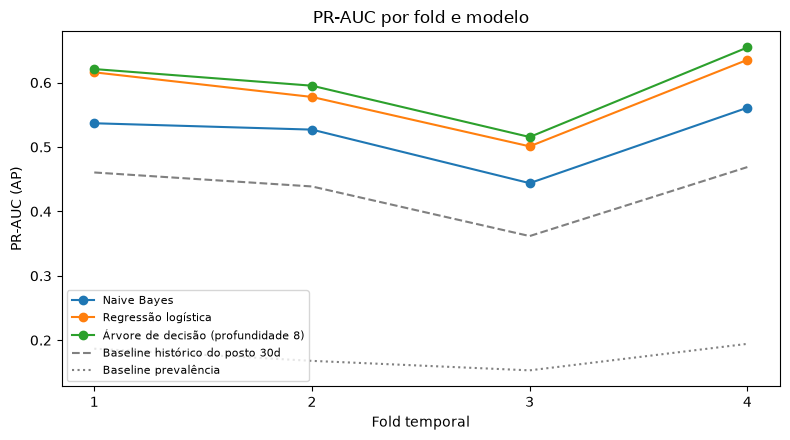

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
for model_name in pr_by_model.columns:
    ax.plot(pr_by_model.index, pr_by_model[model_name], marker="o", label=model_name)
ax.plot(baselines.index.str.replace("fold ", "").astype(int), baselines["Baseline histórico do posto 30d (PR-AUC)"],
        ls="--", color="gray", label="Baseline histórico do posto 30d")
ax.plot(baselines.index.str.replace("fold ", "").astype(int), baselines["Baseline prevalência (PR-AUC)"],
        ls=":", color="gray", label="Baseline prevalência")
ax.set(xlabel="Fold temporal", ylabel="PR-AUC (AP)", title="PR-AUC por fold e modelo", xticks=list(pr_by_model.index))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6. Conclusões da avaliação individual

A tabela reúne a evidência principal por modelo e a figura mostra como o limiar muda o compromisso entre recall e precision e o volume de alertas. As conclusões seguem-se.

In [13]:
validation_prevalence = float(np.mean([y.iloc[va].mean() for _, va in folds]))
history_baseline = baseline_means["Baseline histórico do posto 30d (PR-AUC)"]

summary = pd.DataFrame({
    "PR-AUC média": mean_table["PR-AUC (AP)"],
    "PR-AUC pior fold": worst_table["PR-AUC (AP)"],
    "Ganho sobre o baseline do histórico": mean_table["PR-AUC (AP)"] - history_baseline,
    "Precision (0,2)": mean_table["Precision"],
    "Recall (0,2)": mean_table["Recall"],
    "F2 (0,2)": mean_table["F2"],
    "Brier": mean_table["Brier"],
    "Alertas por 1000 (0,2)": mean_table["Alertas por 1000"],
}).sort_values("PR-AUC média", ascending=False)

display(
    summary.style
    .format("{:.3f}", subset=[col for col in summary.columns if not col.startswith("Alertas")])
    .format("{:.0f}", subset=["Alertas por 1000 (0,2)"])
    .highlight_max(axis=0, color="#d4edda", subset=[col for col in summary.columns if col not in ("Brier", "Alertas por 1000 (0,2)")])
    .highlight_min(axis=0, color="#d4edda", subset=["Brier"])
)
print(f"Verde = melhor valor da coluna. Referência: baseline do histórico = {history_baseline:.3f} (PR-AUC) | "
      f"anomalias reais = {validation_prevalence * 1000:.0f} por 1000 sessões.")

,PR-AUC média,PR-AUC pior fold,Ganho sobre o baseline do histórico,"Precision (0,2)","Recall (0,2)","F2 (0,2)",Brier,"Alertas por 1000 (0,2)"
modelo,,,,,,,,
Árvore de decisão (profundidade 8),0.597,0.516,0.164,0.469,0.621,0.582,0.102,233
Regressão logística,0.582,0.501,0.150,0.447,0.630,0.582,0.105,247
Naive Bayes,0.517,0.444,0.085,0.437,0.573,0.539,0.175,232


Verde = melhor valor da coluna. Referência: baseline do histórico = 0.432 (PR-AUC) | anomalias reais = 176 por 1000 sessões.


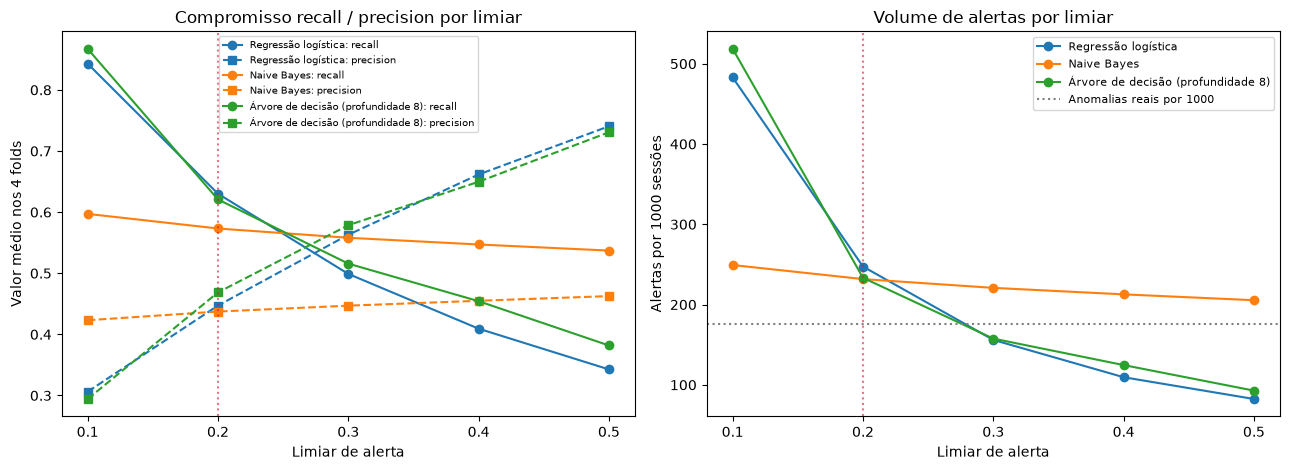

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colors = dict(zip(individual_models, ["tab:blue", "tab:orange", "tab:green"]))

for model_name, color in colors.items():
    data = sensitivity.loc[model_name]
    axes[0].plot(data.index, data["Recall"], color=color, marker="o", label=f"{model_name}: recall")
    axes[0].plot(data.index, data["Precision"], color=color, marker="s", ls="--", label=f"{model_name}: precision")
    axes[1].plot(data.index, data["Alertas por 1000"], color=color, marker="o", label=model_name)

axes[0].set(title="Compromisso recall / precision por limiar", xlabel="Limiar de alerta", ylabel="Valor médio nos 4 folds")
axes[1].axhline(validation_prevalence * 1000, color="gray", ls=":", label="Anomalias reais por 1000")
axes[1].set(title="Volume de alertas por limiar", xlabel="Limiar de alerta", ylabel="Alertas por 1000 sessões")
for ax in axes:
    ax.axvline(THRESHOLD, color="crimson", ls=":", alpha=0.6)
    ax.set_xticks(list(THRESHOLDS))
axes[0].legend(fontsize=7, ncol=1)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

- **Todos superam os baselines.** Os três modelos ficam acima da prevalência (PR-AUC média 0,176) e do histórico do posto a 30 dias (0,432) em todos os folds. Este segundo baseline é o relevante: a regressão logística e a árvore ficam cerca de 0,15 acima dele em PR-AUC média, o Naive Bayes cerca de 0,09.
- **Ordenação estável.** Pela PR-AUC, a árvore (0,597) está à frente da regressão logística (0,582) e esta do Naive Bayes (0,517) nos 4 folds. A vantagem da árvore sobre a regressão logística é pequena (média 0,014, entre 0,005 e 0,019 por fold) mas tem o mesmo sinal em todos os folds. A variação entre períodos (desvio-padrão de cerca de 0,06) é maior do que a diferença entre os dois melhores modelos, por isso a diferença deve ser lida como um indício, não como uma separação clara. O fold 3, com a menor prevalência (0,153), é o mais difícil para todos, e o fold 4 o mais fácil.
- **Com o limiar 0,2 a árvore e a regressão logística são equivalentes.** O F2 médio é igual (0,582). A regressão logística tem mais recall (0,630 contra 0,621) e a árvore mais precision (0,469 contra 0,447); no pior fold, o F2 é melhor na regressão logística (0,536 contra 0,518). A ROC-AUC, secundária, vai no mesmo sentido da PR-AUC (0,826, 0,821 e 0,787). A diferença em PR-AUC não se traduz, a este limiar, numa diferença em F2.
- **O Naive Bayes tem as probabilidades menos fiáveis.** Tem o pior resultado em todas as métricas e um Brier score de 0,175, contra 0,102 e 0,105 nos outros dois. Com o limiar a variar de 0,1 a 0,5, os seus alertas só passam de 249 para 205 por 1000 sessões, enquanto na regressão logística e na árvore passam de cerca de 500 para menos de 100: as probabilidades concentram-se perto de 0 e 1, e o limiar quase não controla o volume de alertas. Isto confirma a violação dos pressupostos apontada na secção 3.1.
- **O limiar condiciona o compromisso.** A 0,1, a regressão logística e a árvore têm recall de 0,84 a 0,87, mas sinalizam cerca de metade das sessões (483 a 519 alertas por 1000, contra cerca de 176 anómalas por 1000 nos folds de validação). A 0,2 sinalizam 233 a 247 por 1000. O limiar final deve ser escolhido com os folds de validação e a razão de custos validada com a operação.
- **A accuracy não foi usada**, porque com 18,6% de sessões anormais não distingue modelos úteis de um que prevê sempre a classe normal.

**Limitações.** A profundidade da árvore foi escolhida nos mesmos folds em que se avalia, por isso a vantagem da árvore pode estar ligeiramente sobrestimada. Com 4 folds, os desvios-padrão e o pior fold são indicativos. Precision, recall, F1 e F2 dependem do limiar provisório de 0,2. Cada princípio é representado por um só algoritmo.

**Para a comparação com os ensembles.** As previsões e métricas por fold estão em `individual_models` e `per_fold`, no mesmo formato e nos mesmos folds, para comparar diretamente com a Random Forest e o *boosting*. A referência a superar é a árvore (PR-AUC média 0,597), com a regressão logística (0,582) como alternativa mais simples.